# CampusPulse: Conclusions
**Umbrella question:** *Can routine campus data warn a university early enough to act, and how much do those
warnings depend on our data-cleaning decisions?*

| Pulse | Question | Dataset |
|---|---|---|
| ① Academic | Who drops out, and how early can we tell? | UCI 697, Portuguese polytechnic, 4,424 students |
| ② Wellbeing | Which behaviours co-occur with persistent sadness? | CDC YRBS 2023 (20,103 students) + Malaysia survey (n=101) |
| ③ Energy | When does a campus building behave differently? | I-BLEND, IIIT Delhi, 52 months of meter data + teaching calendar |

> Every number below is computed by the code cells in this notebook, not typed in.

In [1]:
import sys, os
from pathlib import Path
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / 'campuspulse').exists():
        sys.path.insert(0, str(cand)); break
os.environ['LOKY_MAX_CPU_COUNT'] = '1'
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from campuspulse.academic import pipeline as A
from campuspulse.wellbeing import pipeline as W
from campuspulse.energy import pipeline as EN
from campuspulse.common.decisions import robustness_matrix, survival_summary, fragility_table, status_matrix, defaults
from campuspulse.common.plots import theme
theme()
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 90)
PULSES = {"① Academic": A, "② Wellbeing": W, "③ Energy": EN}

## 1. Every finding with its simple hypothesis test

In [2]:
rows = []
for name, P in PULSES.items():
    vals, _ = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)
    stat = status_matrix(vals).drop(columns="DEFAULT")
    for fid, ev in P.finding_evidence().items():
        t = ev["test"]
        rows.append({"pulse": name, "finding": fid, "claim": P.FINDINGS[fid], "value": round(vals.loc[fid, "DEFAULT"], 3),
                     "test": t["test"], f"statistic": f"{t['statistic_name']} = {t['statistic']:.2f}", "p": f"{t['p']:.2g}",
                     "decision": t["decision"], "holds": f"{(stat.loc[fid] == 'holds').sum()}/{(stat.loc[fid] != 'n/a').sum()}"})
print(pd.DataFrame(rows).to_string(index=False))

      pulse finding                                                                                                            claim     value                                         test   statistic       p         decision holds
 ① Academic      A1                                                         Debtors drop out more than non-debtors (rate difference)     0.411                        Two-proportion z-test   z = 16.10 2.6e-58        reject H0   4/4
 ① Academic      A2                                                              Scholarship holders drop out less (rate difference)     0.345                        Two-proportion z-test   z = 18.86 2.5e-79        reject H0   4/4
 ① Academic      A3                                                   Dropouts have lower semester-1 grades (grade-point difference)     0.983                    Two-sample t-test (Welch)   t = 18.41 2.7e-68        reject H0   3/4
 ① Academic      A4                     Debt still predicts dropout WITHIN e

## 2. How fragile are the insights?
A finding **holds** if it keeps its sign and stays between ½× and 2× of our default under an alternative choice.

In [3]:
summary, board = [], []
for name, P in PULSES.items():
    vals, _ = robustness_matrix(P.run_pipeline, P.DECISIONS, P.FINDINGS)
    summary.append({"pulse": name, **survival_summary(vals)})
    board.append(fragility_table(vals, P.FINDINGS).assign(pulse=name))
print(pd.DataFrame(summary)[["pulse", "tested", "holds", "weakens", "inflates", "reverses", "survival_rate"]].to_string(index=False))
board = pd.concat(board).sort_values("swing", ascending=False)
print(board[["pulse", "finding", "worst_variant", "default", "worst_value", "change", "verdict"]].round(3).to_string(index=False))

      pulse  tested  holds  weakens  inflates  reverses  survival_rate
 ① Academic      16     15        0         1         0       0.937500
② Wellbeing      24     23        0         1         0       0.958333
   ③ Energy      15     14        1         0         0       0.933333
      pulse finding                           worst_variant   default  worst_value change verdict
 ① Academic      A3                     zero_grade=as_score     0.983        5.387  x5.48 fragile
② Wellbeing      W4              course_standardization=raw     0.245        0.706  x2.88 fragile
   ③ Energy     EN3       meter_gap_imputation=forward_fill 10365.897     4943.270  x2.10 fragile
   ③ Energy     EN1                     resample_freq=daily 17857.608     8981.977  x1.99  robust
 ① Academic      A2                         zero_grade=drop     0.345        0.254  x1.36  robust
② Wellbeing      W1             sleep_cutoff=less_than_6hrs     0.181        0.233  x1.29  robust
 ① Academic      A1           

## 3. How early can a university warn? (① Academic)
If the university contacts the 25% highest-risk students, what share of all eventual dropouts does it reach?

             stage  roc_auc  capture_at_25pct  max_possible_capture
    1 at enrolment    0.852             0.541                 0.639
2 after semester 1    0.935             0.626                 0.639
3 after semester 2    0.949             0.634                 0.639


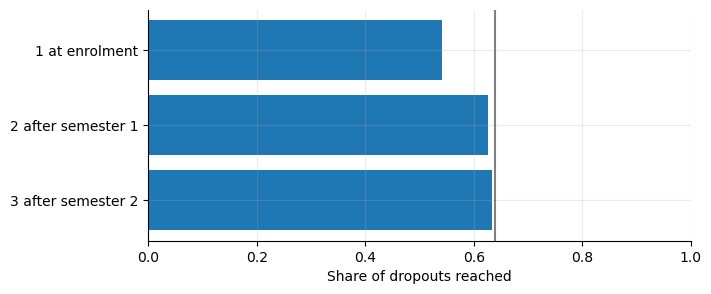

In [4]:
tl = A.run_timeline(A.clean(defaults(A.DECISIONS)))
print(tl[["stage", "roc_auc", "capture_at_25pct", "max_possible_capture"]].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(tl["stage"], tl["capture_at_25pct"]); ax.axvline(tl["max_possible_capture"].iloc[0], color="grey")
ax.set_xlim(0, 1); ax.set_xlabel("Share of dropouts reached"); ax.invert_yaxis()
plt.show()

## 4. Is the energy term effect just the season? (③ Energy)
The I-BLEND calendar marks teaching days and vacations but not exams. Delhi's long vacation is also its hottest
season, so EN3 compares term and vacation nights only within the same calendar month.

In [5]:
st_en = EN.run_stats(EN.clean(defaults(EN.DECISIONS)))
print(st_en["within_month_t"])
print(st_en["by_month"].round(0).to_string(index=False))

{'n_months': 7, 'mean_diff': 8108.378978673681, 't': 2.3046761403449083, 'p': 0.06071010506876763, 'share_months_positive': 0.7142857142857143}
  month  term_rows  vacation_rows  term_mean  vacation_mean    diff
2013-11        145              5    34797.0        40619.0 -5822.0
2014-01        130             18    52968.0        37388.0 15580.0
2014-11        100             10    47767.0        42957.0  4809.0
2015-01         90             15    56940.0        42672.0 14268.0
2017-01        150              5    54649.0        34288.0 20361.0
2017-04        140              5    76106.0        76424.0  -318.0
2017-11        145              5    42337.0        34456.0  7881.0


## 5. Limitations, implications and next steps

**Limitations**
- Three institutions in three countries, none of them ours. We compare *conclusions*, never join rows across datasets.
- Every finding is an association, not a cause.
- YRBS is a high-school survey; the Malaysia survey has n = 101, so W4 is exploratory.
- Hostel power is not a measurement of sleep, and the I-BLEND calendar has no exam dates.
- The robustness matrix changes one decision at a time; combinations are not tested.

**Implications (where the results above support them)**
- A semester-1 checkpoint reaches most future dropouts with a short contact list; fee status and scholarships are cheap signals.
- A cleaning choice can create or hide most of an effect, so dashboards should publish their cleaning decisions.

**Next steps**
- Indian institutional data (AISHE, or our own university with ethics approval) to test which signals transfer.
- Test combinations of decisions, not just one at a time.